# Split Labeled Diagnostic Data (Step 2)

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import umap.umap_ as umap
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import hdbscan
from dotenv import load_dotenv

/home/mariya/miniconda3/envs/pallas/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
load_dotenv()

X_path = os.getenv("LABELED_DIAGNOSTIC_X_CSV_PATH")
y_path = os.getenv("LABELED_DIAGNOSTIC_Y_TSV_PATH")
output_dir = os.getenv("OUTPUT_DIR")
random_seed = int(os.getenv("RANDOM_SEED"))

# Fraction of the data to use for training (default: 0.70).
# The remaining data will be split equally into calibration and test."""
train_frac = float(os.getenv("SPLIT_TRAIN_FRAC", 0.7))

# Minimum number of samples per class that must be available to further split into
# calibration and test sets. Classes not reaching this threshold will be excluded
# from the calibration set (default: 10).
min_calibration_samples = int(os.getenv("SPLIT_MIN_CALIBRATION_SAMPLES", 10))

print("Configuration:")
print(f"X path: {X_path}")
print(f"y path: {y_path}")
print(f"Output dir: {output_dir}")
print(f"Random seed: {random_seed}")
print(f"Train frac: {train_frac}")
print(f"Min calibration samples: {min_calibration_samples}")


Configuration:
X path: /home/mariya/Data/pallas/nf-core-gexml-output/transpose/transposed.csv
y path: /home/mariya/Data/pallas/nf-core-gexml-output/class/subtypes.tsv
Output dir: /home/mariya/Data/pallas/training
Random seed: 42
Train frac: 0.7
Min calibration samples: 10


In [3]:
# Make sure output dir exists
os.makedirs(output_dir, exist_ok=True)

def plot_class_distribution(y_series, title):
    counts = y_series.value_counts().sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    # Change this so the bar also displays the count value on top of each bar
    ax = counts.plot(kind='bar')
    plt.title(title)
    plt.xlabel("Class")
    plt.ylabel("Count")
    plt.xticks(rotation=90)
    for p in ax.patches:
        ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom')
    plt.show()

# Function to save data
def save_data_split(X, y, prefix):
    X.to_csv(f'{output_dir}/pallas.split.labeled_diagnostic.{prefix}.X.csv')
    y.to_csv(f'{output_dir}/pallas.split.labeled_diagnostic.{prefix}.y.tsv', sep='\t')
    plot_class_distribution(y, f'Class Distribution for {prefix} Split')

In [4]:
X = pd.read_csv(X_path, header=0, index_col=0)
X

,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,...,ENSG00000293642,ENSG00000293661,ENSG00000293662,ENSG00000293663,ENSG00000293685,ENSG00000293689,ENSG00000293691,ENSG00000300510,ENSG00000310517,ENSG00000310525
id,,,,,,,,,,,,,,,,,,,,,
16-001,-1.074865,-1.265799,3.833226,3.743114,4.512950,4.344714,0.771073,1.318498,4.365604,6.259711,...,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799
16-002,-0.887961,-1.265799,4.264512,2.305473,4.159496,3.421431,0.699940,2.266916,3.885721,6.498131,...,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799
16-003,-0.905744,-1.265799,3.780698,4.049113,4.525136,2.608914,0.802083,1.952144,4.090735,6.232686,...,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799
16-006,-1.070832,-1.265799,4.003827,3.781629,3.670488,3.674472,-0.761791,1.896970,3.564944,6.670986,...,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799
16-008,2.365082,-1.265799,3.923773,4.277749,3.445142,5.086986,0.410977,2.534783,5.229680,6.912148,...,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SJTALL169_D,-1.265799,-1.265799,4.867897,3.856544,3.809691,3.837370,0.607330,5.308904,5.881071,5.819308,...,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799
SJTALL174_D,-1.019212,-1.265799,3.884678,4.300897,4.707727,4.681853,3.052472,4.124193,4.175947,7.660722,...,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799
SJTALL182_D,-1.265799,-1.265799,3.938846,3.965401,5.888329,4.281461,0.816748,4.320802,5.121624,6.855691,...,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799,-1.265799


In [5]:
target = pd.read_csv(y_path, header=0, index_col=0, sep="\t")
y = target['class']
y

sample
Case_1              Disease,B-ALL,aneuploidy,high hyperdiploid
Case_2             Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1
Case_3             Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1
Case_4            Disease,B-ALL,BCR::ABL1-group,BCR::ABL1-like
Case_5            Disease,B-ALL,BCR::ABL1-group,BCR::ABL1-like
                                      ...                     
SJALL014888                           Disease,B-ALL,TCF3::PBX1
SJBALL020571                            Disease,B-ALL,ZNF384-r
SJBALL020779      Disease,B-ALL,BCR::ABL1-group,BCR::ABL1-like
SJBALL020946        Disease,B-ALL,aneuploidy,high hyperdiploid
SJCOGALL010917     Disease,B-ALL,ETV6::RUNX1-group,ETV6::RUNX1
Name: class, Length: 3352, dtype: object

In [6]:
# Assert that they are the same length
assert len(X) == len(y), f"X and y have different lengths: {len(X)} vs {len(y)}"

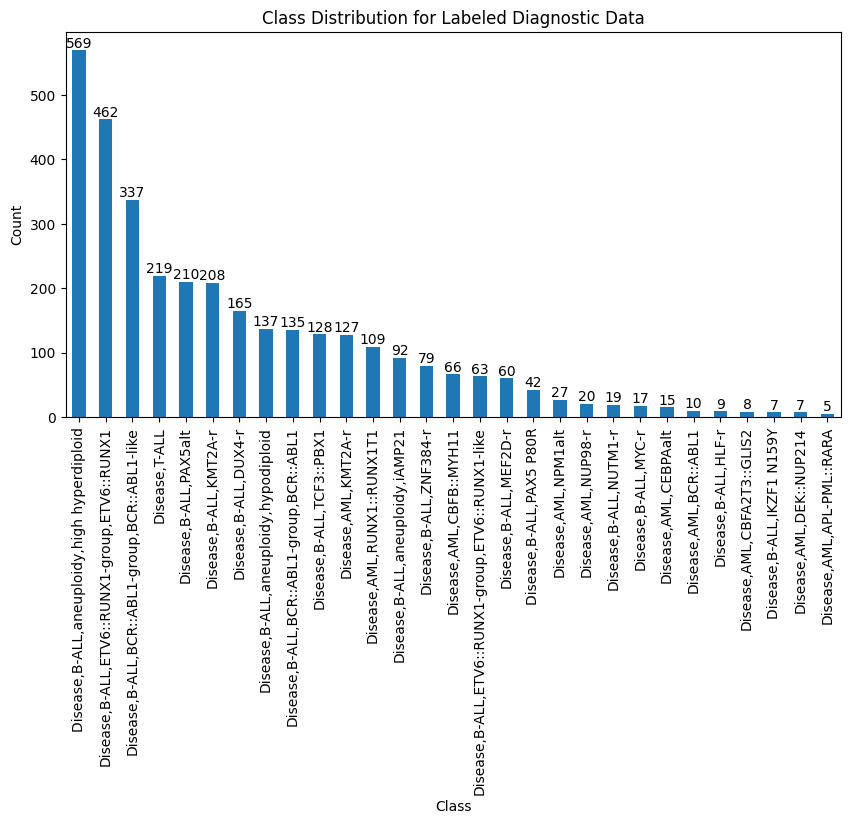

In [7]:
plot_class_distribution(y, "Class Distribution for Labeled Diagnostic Data")

In [8]:
# Align indices
y = y.loc[X.index]

X_train, X_rest, y_train, y_rest = train_test_split(
        X,
        y,
        train_size=train_frac,
        random_state=random_seed,
        stratify=y)

# Print shape of each
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_rest shape: {X_rest.shape}")
print(f"y_rest shape: {y_rest.shape}")

X_train shape: (2346, 19916)
y_train shape: (2346,)
X_rest shape: (1006, 19916)
y_rest shape: (1006,)


In [9]:
# In the rest split, remove samples totaling less
# than the calibration sample minimum.
# Put them into a separate data split.
low_class_indices = y_rest.isin(
    y_rest.value_counts()[
        y_rest.value_counts() < min_calibration_samples].index
)
X_low, y_low = X_rest[low_class_indices], y_rest[low_class_indices]
X_rest = X_rest[~X_rest.index.isin(X_low.index)]
y_rest = y_rest[~y_rest.index.isin(y_low.index)]

# Print all classes in this split and the number of samples in each
print("The following classes will be excluded from the calibration set:")
for class_label in y_low.unique():
    class_count = y_low.value_counts().get(class_label, 0)
    print(f" - Class {class_label}: {class_count} samples")

# Print shape of each
print(f"X_low shape: {X_low.shape}")
print(f"y_low shape: {y_low.shape}")
print(f"X_rest shape: {X_rest.shape}")
print(f"y_rest shape: {y_rest.shape}")

The following classes will be excluded from the calibration set:
 - Class Disease,B-ALL,IKZF1 N159Y: 2 samples
 - Class Disease,AML,BCR::ABL1: 3 samples
 - Class Disease,B-ALL,NUTM1-r: 6 samples
 - Class Disease,AML,DEK::NUP214: 2 samples
 - Class Disease,B-ALL,HLF-r: 3 samples
 - Class Disease,B-ALL,MYC-r: 5 samples
 - Class Disease,AML,CBFA2T3::GLIS2: 2 samples
 - Class Disease,AML,CEBPAalt: 4 samples
 - Class Disease,AML,NUP98-r: 6 samples
 - Class Disease,AML,NPM1alt: 8 samples
 - Class Disease,AML,APL-PML::RARA: 1 samples
X_low shape: (42, 19916)
y_low shape: (42,)
X_rest shape: (964, 19916)
y_rest shape: (964,)


In [10]:
# Split remaining data 50/50
X_calib, X_test, y_calib, y_test = train_test_split(
    X_rest,
    y_rest,
    test_size=0.5,
    random_state=random_seed,
    stratify=y_rest
)

# Print shape of each
print(f"X_calib shape: {X_calib.shape}")
print(f"y_calib shape: {y_calib.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_calib shape: (482, 19916)
y_calib shape: (482,)
X_test shape: (482, 19916)
y_test shape: (482,)


In [11]:
# Merge low items into test set
X_test = pd.concat([X_test, X_low])
y_test = pd.concat([y_test, y_low])

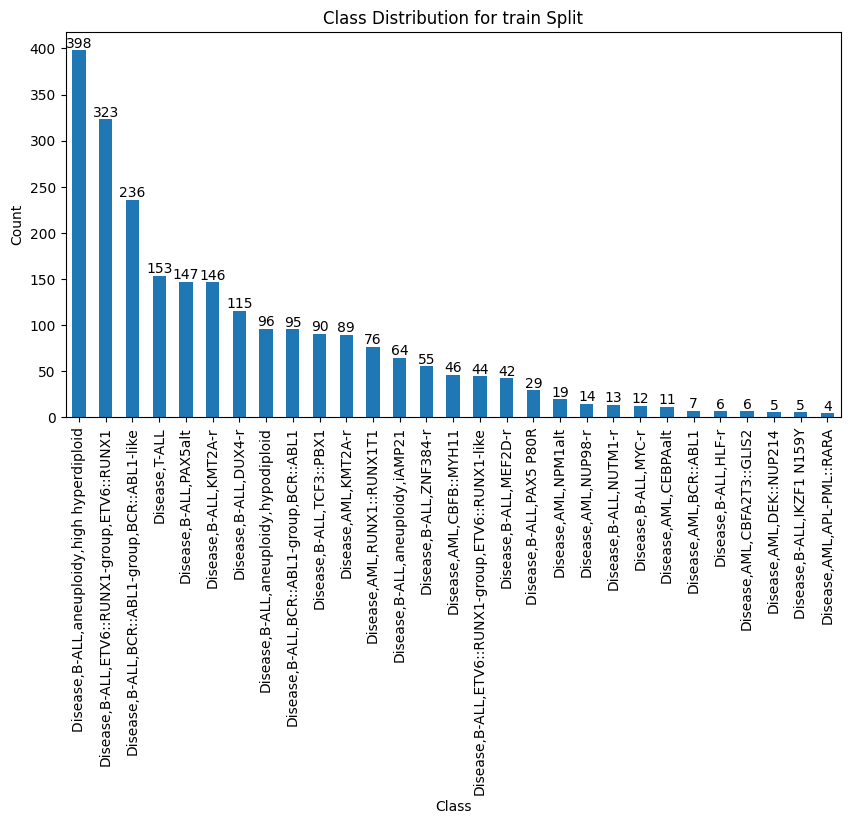

In [12]:
save_data_split(X_train, y_train, "train")


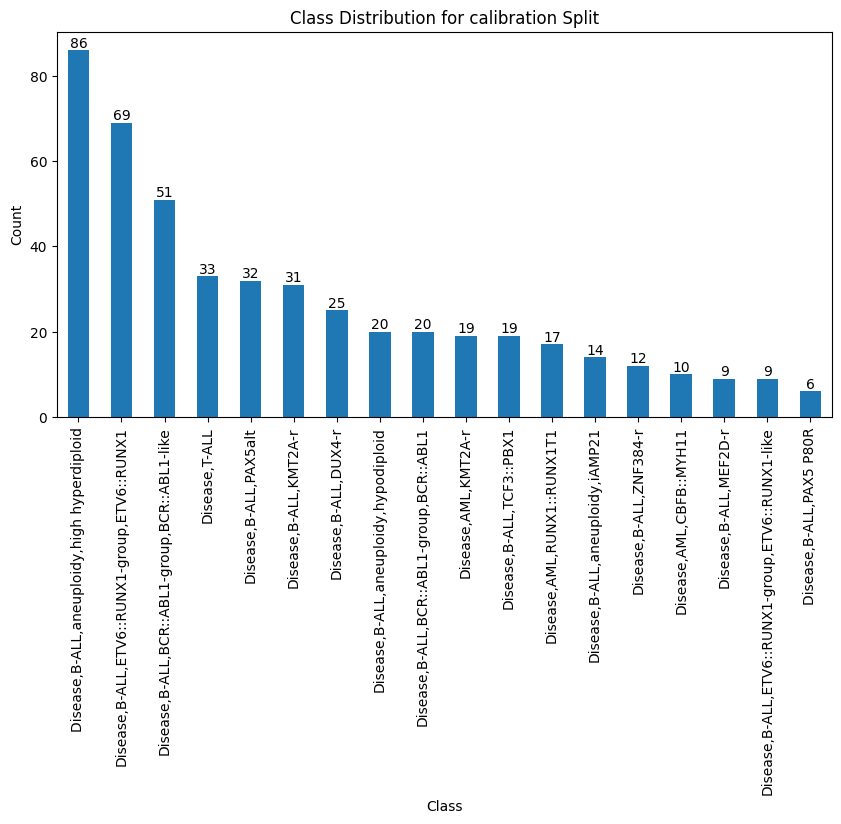

In [13]:
save_data_split(X_calib, y_calib, "calibration")


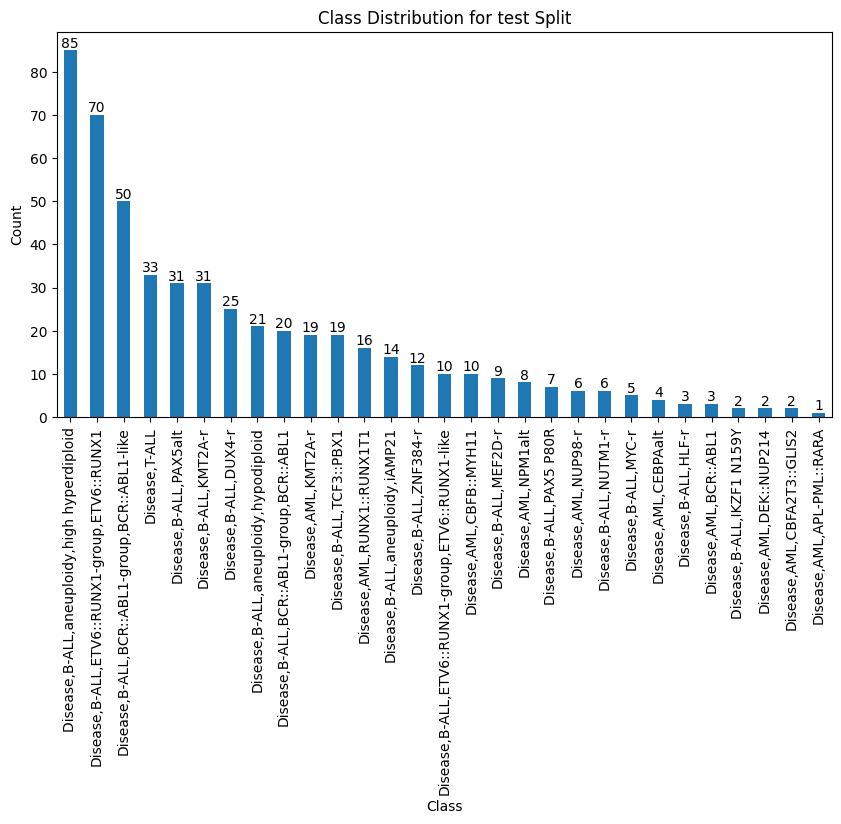

In [14]:
save_data_split(X_test, y_test, "test")


In [15]:
# Print final counts in all sets
print("\nFinal dataset sizes:")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Calibration set: {X_calib.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")


Final dataset sizes:
Training set: 2346 samples
Calibration set: 482 samples
Test set: 524 samples
